# Illustrated image-based profiling workflow

Draws the pycytominer-style pipeline **QC → Normalize → Feature selection → Aggregate → Consensus** as boxes inside dotted frames, with a small cartoon next to each step showing what the operation does to the data.

| Step | pycytominer | What the illustration shows |
|---|---|---|
| QC | – | flag and drop outlier single cells |
| Normalize | `normalize()` | features z-scored relative to negative controls |
| Feature selection | `feature_select()` | low-variance, correlated, NA columns removed |
| Aggregate | `aggregate()` | single cells → one median profile per well |
| Consensus | `aggregate()` (grouped by drug, not well) | replicate wells → one profile per drug |

All illustrations use **simulated data**; they are schematic, not results. Change colours in `COLORS`, and labels/captions in `build_figure()`.

## Setup
Imports, font fallback, random seed, colours and shared heatmap settings.

In [1]:
import pathlib
import textwrap

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager
from matplotlib.patches import Circle, FancyBboxPatch, Polygon, Rectangle
from notebook_init_utils.notebook_init_utils import init_notebook

root_dir, in_notebook = init_notebook()

_AVAILABLE = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = [
    f for f in ("Arial", "Helvetica", "Liberation Sans") if f in _AVAILABLE
] or ["DejaVu Sans"]

RNG = np.random.default_rng(7)

COLORS = {
    "qc": "#F062A8",
    "step": "#DDB8E6",
    "panel_edge": "#A9A9A9",
    "keep": "#4A6FA5",
    "drop": "#D7263D",
    "text_soft": "#555555",
}
CMAP = "RdBu_r"
VLIM = 2.5
N_FEAT = 8

FIG_W_IN = 13.0  # figure width in inches
CANVAS_W = 144  # canvas width in data units (sets the inches-per-unit scale)
IN_PER_UNIT = FIG_W_IN / CANVAS_W

In [2]:
output_figure_file_path = pathlib.Path(
    f"{root_dir}/figures/workflow_figures/figures/profiling_workflow.png"
)
output_figure_file_path.parent.mkdir(parents=True, exist_ok=True)

LOGO_DIR = pathlib.Path(f"{root_dir}/figures/workflow_figures/assets/logos")
COSMICQC_LOGO = LOGO_DIR / "cosmicqc_icon.png"
PYCYTOMINER_LOGO = LOGO_DIR / "pycytominer_icon.png"

## Drawing helpers
The main axes uses data units (0–128 × 0–124, equal aspect), so every box, arrow and inset is placed in those coordinates.

In [ ]:
def rounded_box(ax, x, y, w, h, fc, title=None, subtitle=None, lw=2.5, fontsize=32):
    """Rounded title box; title/subtitle are wrapped to the box width so long
    text never spills past the box border."""
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0,rounding_size=1.2",
            fc=fc,
            ec="black",
            lw=lw,
            zorder=2,
        )
    )
    if title and subtitle:
        wrapped_title = wrap_to_width(title, w * 0.92, fontsize)
        n_title_lines = wrapped_title.count("\n") + 1
        title_line_h = fontsize / 72 / IN_PER_UNIT * 1.15
        shift = (n_title_lines - 1) * title_line_h / 2
        ax.text(
            x + w / 2,
            y + h * 0.60 + shift,
            wrapped_title,
            ha="center",
            va="center",
            fontsize=fontsize,
            zorder=3,
        )
        wrapped_sub = wrap_to_width(subtitle, w * 0.92, 18)
        ax.text(
            x + w / 2,
            y + h * 0.27 - shift,
            wrapped_sub,
            ha="center",
            va="center",
            fontsize=18,
            color=COLORS["text_soft"],
            zorder=3,
        )
    elif title:
        wrapped_title = wrap_to_width(title, w * 0.92, fontsize)
        ax.text(
            x + w / 2,
            y + h / 2,
            wrapped_title,
            ha="center",
            va="center",
            fontsize=fontsize,
            zorder=3,
        )


def wrap_to_width(text, width_units, fontsize, char_w=0.52):
    """Wrap text so each line fits within width_units (data units) at the given fontsize (pt)."""
    max_in = width_units * IN_PER_UNIT
    max_chars = max(1, int(max_in / (fontsize / 72 * char_w)))
    return "\n".join(textwrap.wrap(text, max_chars))


def dotted_frame(ax, x, y, w, h):
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0,rounding_size=2",
            fc="none",
            ec="black",
            lw=2.5,
            ls=(0, (1, 2)),
            zorder=1,
        )
    )


def block_arrow(ax, p0, p1, width=2.4, head_width=6.0, head_len=4.0):
    """Solid black block arrow from p0 to p1 (data coords)."""
    p0, p1 = np.asarray(p0, float), np.asarray(p1, float)
    d = p1 - p0
    length = np.linalg.norm(d)
    d /= length
    n = np.array([-d[1], d[0]])
    neck = p0 + d * (length - head_len)
    pts = [
        p0 + n * width / 2,
        neck + n * width / 2,
        neck + n * head_width / 2,
        p1,
        neck - n * head_width / 2,
        neck - n * width / 2,
        p0 - n * width / 2,
    ]
    ax.add_patch(Polygon(pts, closed=True, fc="black", ec="black", zorder=4))


def mini_arrow(ax, x0, x1, y, label=None, fontsize=16):
    ax.annotate(
        "",
        xy=(x1, y),
        xytext=(x0, y),
        zorder=5,
        arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#333333", mutation_scale=12),
    )
    if label:
        ax.text(
            (x0 + x1) / 2,
            y + 1.0,
            label,
            ha="center",
            va="bottom",
            fontsize=fontsize,
            color="#333333",
            zorder=5,
        )

### Panels, insets and heatmaps
`panel()` draws the white card with a caption and returns the area left for content; `inset()` places a small axes inside it.

In [ ]:
def panel(ax, x, y, w, h, caption, fontsize=19):
    """White card behind an illustration; returns the content rectangle.

    The caption is wrapped to the panel width, and the bottom margin grows
    with the number of wrapped lines so long captions never spill past the
    card's border.
    """
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0,rounding_size=0.8",
            fc="white",
            ec=COLORS["panel_edge"],
            lw=1.0,
            zorder=2,
        )
    )
    wrapped = wrap_to_width(caption, w * 0.94, fontsize)
    n_lines = wrapped.count("\n") + 1
    line_h = fontsize / 72 / IN_PER_UNIT * 1.25
    cap_h = n_lines * line_h
    bottom_margin = 1.0 + cap_h + 1.0
    top_margin = 1.6
    ax.text(
        x + w / 2,
        y + bottom_margin / 2,
        wrapped,
        ha="center",
        va="center",
        fontsize=fontsize,
        style="italic",
        color=COLORS["text_soft"],
        zorder=3,
    )
    return x + 1.0, y + bottom_margin, w - 2.0, h - bottom_margin - top_margin


def inset(ax, x, y, w, h):
    a = ax.inset_axes([x, y, w, h], transform=ax.transData)
    a.set_zorder(6)
    return a


def heatmap(a, data, ylabels=None, ylabel_colors=None, ylabel_fontsize=15):
    cmap = plt.get_cmap(CMAP).copy()
    cmap.set_bad("white")
    a.imshow(
        data, cmap=cmap, vmin=-VLIM, vmax=VLIM, aspect="auto", interpolation="nearest"
    )
    a.set_xticks([])
    if ylabels is None:
        a.set_yticks([])
    else:
        a.set_yticks(range(len(ylabels)))
        a.set_yticklabels(ylabels, fontsize=ylabel_fontsize)
        a.tick_params(axis="y", length=0, pad=1.5)
        if ylabel_colors:
            for t, c in zip(a.get_yticklabels(), ylabel_colors):
                t.set_color(c)
                t.set_fontweight("bold")
    for s in a.spines.values():
        s.set_linewidth(0.6)


def tiny_title(a, text):
    a.set_title(text, fontsize=17, pad=2, color="#333333")

## Step illustrations

### Quality control
Scatter of single cells (nucleus area vs DNA intensity). Cells outside the dashed gate, such as merged nuclei or debris, are flagged with a red ✕ and dropped.

In [ ]:
def draw_qc(ax, rect):
    """Scatter of single cells; outliers outside the QC gate are dropped.
    A row of whole-organoid icons makes the same point at the organoid
    level: coSMicQC also flags and drops abnormally small/large organoids,
    not just individual outlier cells."""
    x, y, w, h = rect

    # ---- organoid-level outliers (size-based) --------------------------- #
    # Reserved band at the top of the panel for the caption + icon row;
    # anchored with `va="top"`/explicit radii so nothing crosses the
    # panel's own border above it.
    row_h = 5.5
    cap_y = y + h - 0.2
    org_y = y + h - 4.3
    sizes = [0.52, 0.58, 0.5, 1.1, 0.56, 0.6, 0.38, 0.54]
    org_drop = [False, False, False, True, False, False, True, False]
    org_xs = np.linspace(x + 2.3, x + w - 2.3, len(sizes))
    for ox, s, dropped in zip(org_xs, sizes, org_drop):
        r = 0.95 * s
        ax.add_patch(
            Circle(
                (ox, org_y),
                r,
                fc=COLORS["drop"] if dropped else "#E7E9ED",
                ec=COLORS["drop"] if dropped else "#777777",
                lw=1.2,
                alpha=0.9 if dropped else 1.0,
                zorder=5,
            )
        )
        if dropped:
            # scale the X mark with the circle so it reads cleanly on the
            # undersized organoid too, not just the oversized one
            ax.plot(
                ox,
                org_y,
                marker="x",
                color="white",
                ms=max(3.5, r * 7.5),
                mew=1.6,
                zorder=6,
            )
    ax.text(
        x + w / 2,
        cap_y,
        "organoids: size/shape outliers dropped too",
        ha="center",
        va="top",
        fontsize=13,
        style="italic",
        color=COLORS["text_soft"],
    )

    # ---- single-cell scatter --------------------------------------------- #
    # Extra left padding (2.6 instead of 1.5) keeps the rotated "DNA
    # intensity" ylabel clear of the panel's own border.
    a = inset(ax, x + 2.6, y + 1.0, w - 3.6, h - row_h - 0.7)

    n = 260
    area = RNG.normal(0, 1, n)
    intensity = 0.5 * area + RNG.normal(0, 0.85, n)
    # a few segmentation failures: merged blobs / debris
    area = np.concatenate([area, RNG.normal(4.2, 0.4, 7), RNG.normal(-3.6, 0.3, 6)])
    intensity = np.concatenate(
        [intensity, RNG.normal(3.6, 0.5, 7), RNG.normal(-3.3, 0.4, 6)]
    )

    lo, hi = -2.6, 2.6
    bad = (area < lo) | (area > hi) | (intensity < lo) | (intensity > hi)

    a.scatter(area[~bad], intensity[~bad], s=5, c=COLORS["keep"], alpha=0.6, lw=0)
    a.scatter(area[bad], intensity[bad], s=18, c=COLORS["drop"], marker="x", lw=1.3)
    a.add_patch(
        Rectangle((lo, lo), hi - lo, hi - lo, fill=False, ls="--", lw=1.0, ec="#333333")
    )
    a.text(
        hi - 0.1,
        lo + 0.15,
        "keep",
        fontsize=16,
        ha="right",
        va="bottom",
        color=COLORS["keep"],
        fontweight="bold",
    )
    a.text(
        4.6,
        2.4,
        "drop",
        fontsize=16,
        ha="right",
        va="top",
        color=COLORS["drop"],
        fontweight="bold",
    )
    a.set_xlim(-5, 5.4)
    a.set_ylim(-5, 5.2)
    a.set_xticks([])
    a.set_yticks([])
    a.set_xlabel("nucleus area", fontsize=16, labelpad=1)
    a.set_ylabel("DNA intensity", fontsize=16, labelpad=4)
    for s in a.spines.values():
        s.set_linewidth(0.6)

### Normalize
Raw features live on very different scales; after `normalize()` (e.g. `standardize` or `mad_robustize` against negative controls) they are centred at 0 with unit spread.

In [ ]:
def draw_normalize(ax, rect):
    """Features on different scales -> centred & scaled relative to controls."""
    x, y, w, h = rect
    left = inset(ax, x, y, w * 0.40, h - 1.2)
    right = inset(ax, x + w * 0.60, y, w * 0.40, h - 1.2)

    colors = ["#7B2D8E", "#E07A1F", "#2E86AB"]
    raw = [(2.0, 0.7), (6.0, 1.5), (11.0, 2.4)]
    xs = np.linspace(-1, 18, 400)
    for (mu, sd), c in zip(raw, colors):
        pdf = np.exp(-0.5 * ((xs - mu) / sd) ** 2) / sd
        left.fill_between(xs, pdf, color=c, alpha=0.35, lw=0)
        left.plot(xs, pdf, color=c, lw=1.2)
    tiny_title(left, "raw features")

    zs = np.linspace(-4, 4, 300)
    for i, c in enumerate(colors):
        sd = 1 + 0.06 * (i - 1)
        pdf = np.exp(-0.5 * (zs / sd) ** 2) / sd
        right.fill_between(zs, pdf, color=c, alpha=0.25, lw=0)
        right.plot(zs, pdf, color=c, lw=1.2)
    right.axvline(0, color="#333333", lw=0.8, ls=":")
    tiny_title(right, "normalized (z)")

    for a in (left, right):
        a.set_xticks([])
        a.set_yticks([])
        for s in ("top", "right", "left"):
            a.spines[s].set_visible(False)
        a.spines["bottom"].set_linewidth(0.6)

    mini_arrow(ax, x + w * 0.42, x + w * 0.58, y + h * 0.45, "(x − μ) / σ", fontsize=14)

### Feature selection
A cells × features matrix. `feature_select()` removes a near-constant column (variance), one of a highly correlated pair, and a mostly-missing column (NA); the remaining features carry on.

In [ ]:
def draw_feature_select(ax, rect):
    """Feature matrix with low-variance, correlated and NA columns removed."""
    x, y, w, h = rect
    n_rows, n_cols = 7, 12
    data = RNG.normal(0, 1.1, (n_rows, n_cols))

    var_col, corr_pair, na_col = 2, (5, 6), 9
    data[:, var_col] = 0.15 + RNG.normal(0, 0.03, n_rows)  # ~constant
    data[:, corr_pair[1]] = data[:, corr_pair[0]] + RNG.normal(0, 0.12, n_rows)
    data[RNG.choice(n_rows, 4, replace=False), na_col] = np.nan  # mostly missing
    dropped = {var_col: "var", corr_pair[1]: "corr", na_col: "NA"}

    lw_frac = 0.52
    left = inset(ax, x, y + 1.8, w * lw_frac, h - 5.0)
    heatmap(left, data)
    for r, c in zip(*np.where(np.isnan(data))):
        left.add_patch(
            Rectangle(
                (c - 0.5, r - 0.5), 1, 1, fill=False, hatch="////", ec="#AAAAAA", lw=0
            )
        )
    for c, why in dropped.items():
        left.axvspan(c - 0.5, c + 0.5, color="white", alpha=0.55, lw=0)
        left.plot(
            c, -1.0, marker="x", color=COLORS["drop"], ms=5, mew=1.8, clip_on=False
        )
        left.text(
            c,
            -1.6,
            why,
            ha="center",
            va="bottom",
            fontsize=15,
            color=COLORS["drop"],
            clip_on=False,
        )
    left.set_ylim(n_rows - 0.5, -0.5)

    keep = [c for c in range(n_cols) if c not in dropped]
    rw = w * lw_frac * len(keep) / n_cols
    right = inset(ax, x + w - rw, y + 1.8, rw, h - 3.4)
    heatmap(right, data[:, keep])
    tiny_title(right, f"{len(keep)} of {n_cols} kept")

    mini_arrow(ax, x + w * lw_frac + 1.0, x + w - rw - 1.0, y + h * 0.5)

### Aggregate: well median
Each well contains many single cells; `aggregate()` takes the per-feature median to give one profile per well.

In [ ]:
def draw_well_median(ax, rect):
    """Many single cells per well -> one median profile per well."""
    x, y, w, h = rect
    wells = ["A01", "A02", "A03"]
    well_means = RNG.normal(0, 1.3, (len(wells), N_FEAT))

    # Same top clearance as the "well profiles" inset below (h - 2.2, not
    # h - 0.4), so its tiny_title doesn't collide with the panel's own
    # border above it.
    left = inset(ax, x, y, w * 0.52, h - 2.2)
    left.set_xlim(-0.2, 7.0)
    left.set_ylim(-1.75, 1.25)
    left.set_aspect("equal", adjustable="box")
    left.axis("off")

    medians = []
    for i, name in enumerate(wells):
        cx = 1.1 + i * 2.4
        n_cells = 22
        cells = well_means[i] + RNG.normal(0, 0.9, (n_cells, N_FEAT))
        medians.append(np.median(cells, axis=0))
        left.add_patch(Circle((cx, 0), 1.0, fc="#F4F4F4", ec="#555555", lw=1.0))
        r = 0.8 * np.sqrt(RNG.uniform(0, 1, n_cells))
        t = RNG.uniform(0, 2 * np.pi, n_cells)
        left.scatter(
            cx + r * np.cos(t),
            r * np.sin(t),
            s=7,
            c=cells[:, 0],
            cmap=CMAP,
            vmin=-VLIM,
            vmax=VLIM,
            lw=0.2,
            ec="#333333",
        )
        left.text(cx, -1.25, name, ha="center", va="top", fontsize=16)
    tiny_title(left, "single cells per well")

    right = inset(ax, x + w * 0.78, y + 0.8, w * 0.22, h - 2.2)
    heatmap(right, np.array(medians), ylabels=wells)
    tiny_title(right, "well profiles")

    mini_arrow(ax, x + w * 0.54, x + w * 0.62, y + h * 0.45, "median")

### Consensus: per drug
Replicate wells treated with the same drug are combined (median across replicates) into one consensus profile per drug.
This reuses `aggregate()` with a different `strata`/groupby (drug instead of well) rather than a separate `consensus()` call.

In [ ]:
def draw_consensus(ax, rect):
    """Replicate well profiles of the same drug -> one consensus profile."""
    x, y, w, h = rect
    drugs = {"A": "#7B2D8E", "B": "#E07A1F"}
    n_rep = 3

    rows, labels, label_colors, consensus = [], [], [], []
    for d, col in drugs.items():
        effect = RNG.normal(0, 1.4, N_FEAT)
        reps = effect + RNG.normal(0, 0.55, (n_rep, N_FEAT))
        rows.append(reps)
        consensus.append(np.median(reps, axis=0))
        labels += [f"{d}·rep{i + 1}" for i in range(n_rep)]
        label_colors += [col] * n_rep
    rows = np.vstack(rows)

    left = inset(ax, x + 7.0, y + 1.3, w * 0.32, h - 2.6)
    # 6 rows need a much smaller label font than the 2-3 row heatmaps
    # elsewhere, or the labels overlap each other vertically.
    heatmap(left, rows, ylabels=labels, ylabel_colors=label_colors, ylabel_fontsize=9)
    left.axhline(n_rep - 0.5, color="black", lw=1.2)
    tiny_title(left, "replicate wells")

    right = inset(ax, x + w * 0.74, y + 1.6, w * 0.26, h - 4.0)
    heatmap(
        right,
        np.array(consensus),
        ylabels=[f"drug {d}" for d in drugs],
        ylabel_colors=list(drugs.values()),
    )
    tiny_title(right, "consensus")

    mini_arrow(ax, x + w * 0.47, x + w * 0.60, y + h * 0.45, "median")

## Decorative icons
The coSMicQC and pycytominer badges are each project's own open-source logo (fetched from
their GitHub repos: `cytomining/coSMicQC` and `cytomining/pycytominer`), not redrawn here.

In [10]:
def logo_badge(ax, cx, cy, logo_path, half=8.0, zorder=4):
    """Place a software project's own logo image, centred at (cx, cy)."""
    img = plt.imread(logo_path)
    ax.imshow(img, extent=(cx - half, cx + half, cy - half, cy + half), zorder=zorder)


def box_logo(ax, box_x, box_y, box_w, box_h, logo_path, half=3.2, margin=1.2):
    """Small software-logo badge in the top-left corner of an operation box."""
    logo_badge(
        ax,
        box_x + margin + half,
        box_y + box_h - margin - half,
        logo_path,
        half=half,
        zorder=4,
    )

## Assemble the figure
Positions of every frame, box and panel are set here. Edit the `steps` list to rename steps or change captions.

In [ ]:
def build_figure():
    W, H = CANVAS_W, 124  # canvas in data units
    fig = plt.figure(figsize=(FIG_W_IN, FIG_W_IN * H / W))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W)
    ax.set_ylim(0, H)
    ax.set_aspect("equal")
    ax.axis("off")

    # Each software logo sits inside the operation box(es) it belongs to,
    # leaving the full width between the boxes and the frame edge for the
    # illustration panels.
    BOX_X, BOX_W = 10, 54  # step boxes (wide enough for large titles)
    PAN_X, PAN_W = 67, 68  # illustration panels

    # ---- top: QC ---------------------------------------------------------#
    qc_box_h = 11
    rounded_box(
        ax, BOX_X, 103, BOX_W, qc_box_h, COLORS["qc"], "Quality Control", fontsize=34
    )
    box_logo(ax, BOX_X, 103, BOX_W, qc_box_h, COSMICQC_LOGO)
    qc_rect = panel(
        ax,
        PAN_X,
        97.5,
        PAN_W,
        23.5,
        "flag & remove outlier cells (segmentation errors, debris)",
    )
    draw_qc(ax, qc_rect)

    arrow_x = BOX_X + BOX_W / 2
    block_arrow(
        ax, (arrow_x, 102.5), (arrow_x, 89.5), width=3.0, head_width=7.5, head_len=4.5
    )

    # ---- bottom: pycytominer steps ---------------------------------------#
    step_h, gap = 20.5, 1.5
    steps = [
        (
            "Normalize",
            "normalize()",
            draw_normalize,
            "scale each feature relative to negative controls",
        ),
        (
            "Feature selection",
            "feature_select()",
            draw_feature_select,
            "drop low-variance, correlated, NA & blocklisted features",
        ),
        (
            "Aggregate",
            "aggregate()  ·  well median",
            draw_well_median,
            "single-cell profiles → one median profile per well",
        ),
        (
            "Consensus",
            "aggregate()  ·  per drug",
            draw_consensus,
            "replicate wells → one consensus profile per drug",
        ),
    ]
    top = 89.5
    ys = []
    box_h = step_h - 3
    for i, (title, sub, draw, caption) in enumerate(steps):
        y0 = top - (i + 1) * step_h - i * gap
        ys.append(y0)
        box_y = y0 + 1.5
        rounded_box(ax, BOX_X, box_y, BOX_W, box_h, COLORS["step"], title, sub)
        box_logo(ax, BOX_X, box_y, BOX_W, box_h, PYCYTOMINER_LOGO)
        draw(ax, panel(ax, PAN_X, y0, PAN_W, step_h, caption))

    # bracket grouping the two aggregation forms
    bx, y_lo, y_hi = 7.0, ys[3] + 1.5, ys[2] + step_h - 1.5
    ax.plot(
        [bx + 1.2, bx, bx, bx + 1.2],
        [y_hi, y_hi, y_lo, y_lo],
        color="black",
        lw=1.5,
        zorder=3,
    )
    ax.text(
        bx - 1.6,
        (y_lo + y_hi) / 2,
        "aggregation",
        rotation=90,
        ha="center",
        va="center",
        fontsize=18,
        color=COLORS["text_soft"],
    )

    return fig

## Render

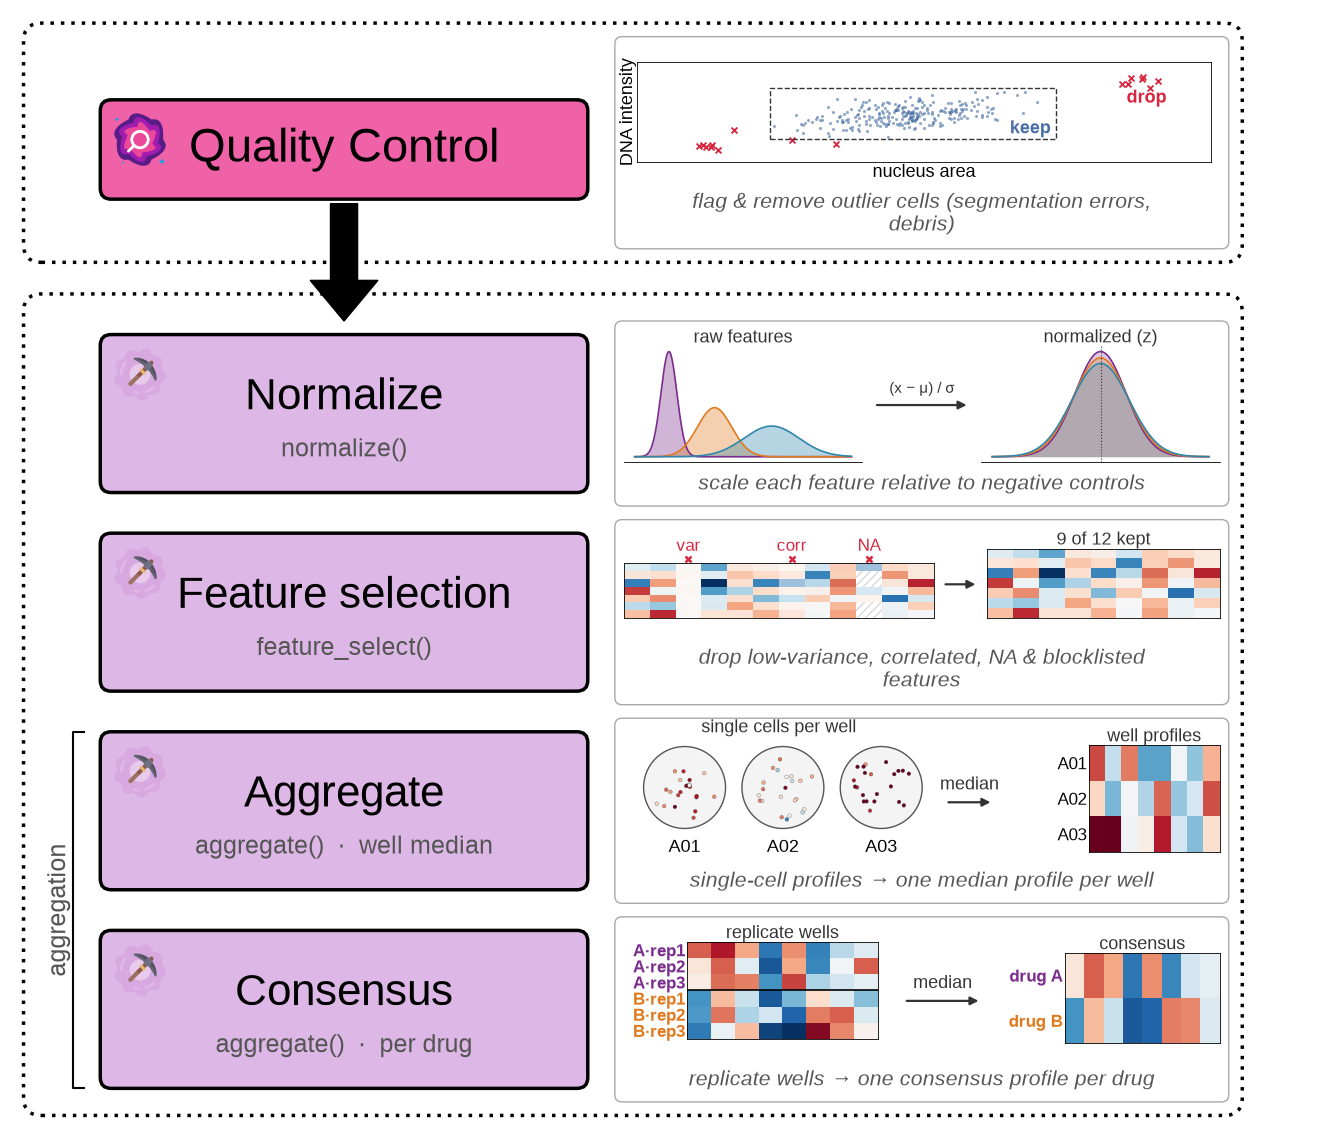

In [12]:
fig = build_figure()
plt.show()

## Save
The format follows the file extension (png, svg, pdf, …). SVG is the easiest to tweak afterwards in Illustrator or Inkscape.

In [13]:
fig.savefig(output_figure_file_path, dpi=300, facecolor="white")